# What makes a house expensive?### Multivariate Linear Regression · from scratch · ≈ 2 hoursLast lecture you watched the matrix form of linear regression take shape on the board — one row of weights, one matrix of features, and the whole dataset's predictions tumble out in a single multiplication. Today you'll turn that math into working code and point it at a real dataset: **house prices in California**.Eight numbers describe each neighborhood — median income, number of rooms, how old the houses are, latitude, longitude, and so on. From those eight numbers, you'll predict the median house value. Your model will be a vector of eight weights that says, in effect: *"here is how much each thing matters."*### What you will build1. A `MultivariateLinearRegression` class with vectorized `fit` and `predict`2. A loss curve that proves gradient descent is doing its job3. **A learning-rate playground** — the single most important hyperparameter in all of ML4. A ranked feature-importance plot answering the question the title asks### Ground rules- Only **NumPy**, **Matplotlib**, and sklearn (for data loading and the final comparison)- No `sklearn.linear_model.LinearRegression` until the very last section- Keep your math vectorized. If you find yourself writing a `for` loop over training examples, stop and think about how a matrix multiply would do the same thing in one line.Let's build.

---## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

---## 2. The dataThe **California Housing** dataset: 20,640 California census blocks, each described by 8 features. The target is the **median house value** in that block, in units of $100,000.| Feature | What it is ||---|---|| `MedInc` | median income in the block (tens of thousands) || `HouseAge` | median house age (years) || `AveRooms` | average rooms per household || `AveBedrms` | average bedrooms per household || `Population` | block population || `AveOccup` | average household occupants || `Latitude` | geographic latitude || `Longitude` | geographic longitude |Before you train anything, go look at the data. Which features are on wildly different scales? Which ones do you expect to matter? Write down two guesses before you see the answer in Section 6.

In [2]:
housing = fetch_california_housing()
X = housing.data
y = housing.target
feature_names = housing.feature_names

print(f"Features: {X.shape},   Target: {y.shape}")
print(f"Feature names: {feature_names}")
print(f"\nFirst 3 rows:\n{X[:3]}")
print(f"\nTarget range: ${y.min()*100:.0f}k  —  ${y.max()*100:.0f}k")

Features: (20640, 8),   Target: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

First 3 rows:
[[ 8.32520000e+00  4.10000000e+01  6.98412698e+00  1.02380952e+00
   3.22000000e+02  2.55555556e+00  3.78800000e+01 -1.22230000e+02]
 [ 8.30140000e+00  2.10000000e+01  6.23813708e+00  9.71880492e-01
   2.40100000e+03  2.10984183e+00  3.78600000e+01 -1.22220000e+02]
 [ 7.25740000e+00  5.20000000e+01  8.28813559e+00  1.07344633e+00
   4.96000000e+02  2.80225989e+00  3.78500000e+01 -1.22240000e+02]]

Target range: $15k  —  $500k


### 2.1 Why standardization is not optional hereLook at the scales. `MedInc` is around 3–8; `Population` is in the thousands; `Latitude` is 32–42. If you feed these to gradient descent as-is, the gradient for `Population` will dominate — not because population matters more, but because its numbers are bigger. The learning rate that works for one feature will overshoot for another.**Task:** Split the data 80/20 (random_state=42), then standardize the features. Fit the scaler on the training set only.

In [3]:
# Split, standardize. Short.
# YOUR CODE HERE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape},  Test: {X_test_scaled.shape}")
print(f"Train means (should all be ~0): {X_train_scaled.mean(axis=0).round(3)}")
print(f"Train stds  (should all be ~1): {X_train_scaled.std(axis=0).round(3)}")

Train: (16512, 8),  Test: (4128, 8)
Train means (should all be ~0): [-0. -0.  0. -0. -0. -0.  0. -0.]
Train stds  (should all be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


---## 3. Build itHere is the math from the lecture, in one place.**Hypothesis** (for the whole training set at once):$$h_\theta(X) = X\theta + b$$**Cost** (half-mean-squared-error):$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)}) - y^{(i)}\right)^2$$**Gradient** (for every weight at once):$$\frac{\partial J}{\partial\theta} = \frac{1}{m}X^T(h_\theta(X) - y)$$**Update:** $\theta \leftarrow \theta - \alpha \cdot \nabla J$Your class should expose `fit`, `predict`, and keep a `loss_history`. Beyond that, how you structure it is up to you. Keep it vectorized — any `for` loop over training examples is a bug.

In [4]:
class MultivariateLinearRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
        # YOUR CODE HERE (any other state you need)
        self.weights = None
        self.bias = 0.0
        self.diverged = False

    def fit(self, X, y):
        # Initialize weights and bias, then run gradient descent.
        # Append the cost to self.loss_history every iteration.
        # YOUR CODE HERE
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim != 2 or X.shape[0] != y.size:
            raise ValueError("X must be 2-D with one row per target value")
        m, n = X.shape
        self.weights = np.zeros(n, dtype=float)
        self.bias = 0.0
        self.loss_history = []
        self.diverged = False

        for _ in range(self.n_iterations):  # loop over iterations, not examples
            with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
                errors = X @ self.weights + self.bias - y
                loss = np.dot(errors, errors) / (2 * m)
                if not np.isfinite(loss):
                    self.diverged = True
                    break
                self.loss_history.append(float(loss))
                gradient_w = (X.T @ errors) / m
                gradient_b = np.mean(errors)
                new_weights = self.weights - self.learning_rate * gradient_w
                new_bias = self.bias - self.learning_rate * gradient_b

            if not (np.all(np.isfinite(new_weights)) and np.isfinite(new_bias)):
                self.diverged = True
                break
            self.weights = new_weights
            self.bias = float(new_bias)
        return self

    def predict(self, X):
        # YOUR CODE HERE
        # pass
        if self.weights is None:
            raise RuntimeError("Call fit() before predict().")
        X = np.asarray(X, dtype=float)
        return X @ self.weights + self.bias

---## 4. First training runTrain with `learning_rate=0.1` and `n_iterations=1000`. Then plot the loss curve.

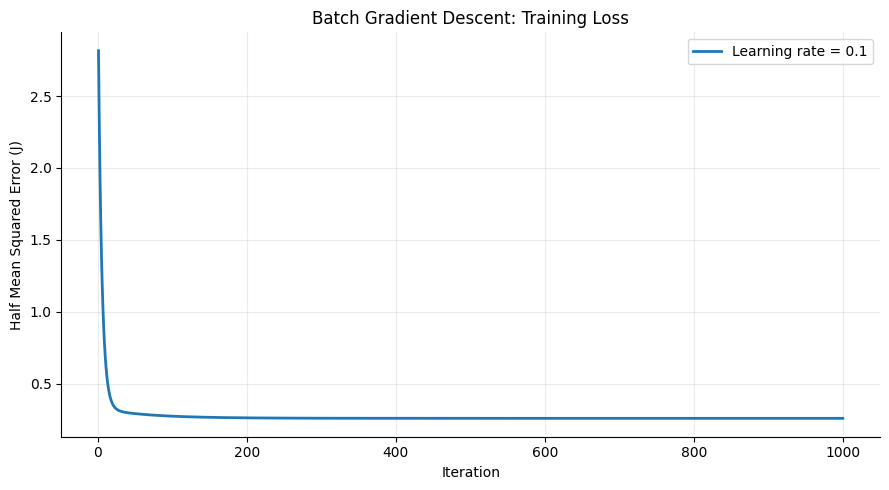

Starting loss: 2.814871
Final loss:    0.258967


In [5]:
# Train and plot the loss curve.
# YOUR CODE HERE
model = MultivariateLinearRegression(learning_rate=0.1, n_iterations=1000)
model.fit(X_train_scaled, y_train)

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history,
         linewidth=2, label="Learning rate = 0.1")
plt.title("Batch Gradient Descent: Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Half Mean Squared Error (J)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()
print(f"Starting loss: {model.loss_history[0]:.6f}")
print(f"Final loss:    {model.loss_history[-1]:.6f}")

Compute test-set **RMSE** (root mean squared error) in the original dollar units. Since `y` is in units of $100k, multiply by 100 to get an answer in thousands of dollars.> RMSE = √( mean( (y_true − y_pred)² ) )

In [6]:
# RMSE on test set, in thousands of dollars.
# YOUR CODE HERE
predictions = model.predict(X_test_scaled)
rmse_custom_k = np.sqrt(np.mean((y_test - predictions) ** 2)) * 100
print(f"Test RMSE (from scratch): ${rmse_custom_k:,.2f}k")

Test RMSE (from scratch): $74.57k


---## 5. The learning-rate playgroundThis is the part where everything you've heard about gradient descent becomes real.Train your model with **six different learning rates**:```α ∈ { 0.001, 0.01, 0.1, 0.3, 1.0, 3.0 }```Keep `n_iterations=1000` for all of them. **Plot all six loss curves on one figure** (use a log scale on the y-axis — it makes very different losses comparable). Then write a short paragraph answering:1. Which α converged fastest?2. Which α converged to the lowest loss?3. What happens with α = 3.0? Why?4. What happens with α = 0.001? Why?If a run diverges (NaN or inf), that's not a bug in your code — it's the point of this exercise. Catch the NaN and plot what you have.

α=0.001 | completed | iterations=1000 | last loss=0.655678
α=0.01  | completed | iterations=1000 | last loss=0.273862
α=0.1   | completed | iterations=1000 | last loss=0.258967
α=0.3   | completed | iterations=1000 | last loss=0.258967
α=1     | completed | iterations=1000 | last loss=3.31891e+18
α=3     | diverged  | iterations= 218 | last loss=1.49958e+303


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


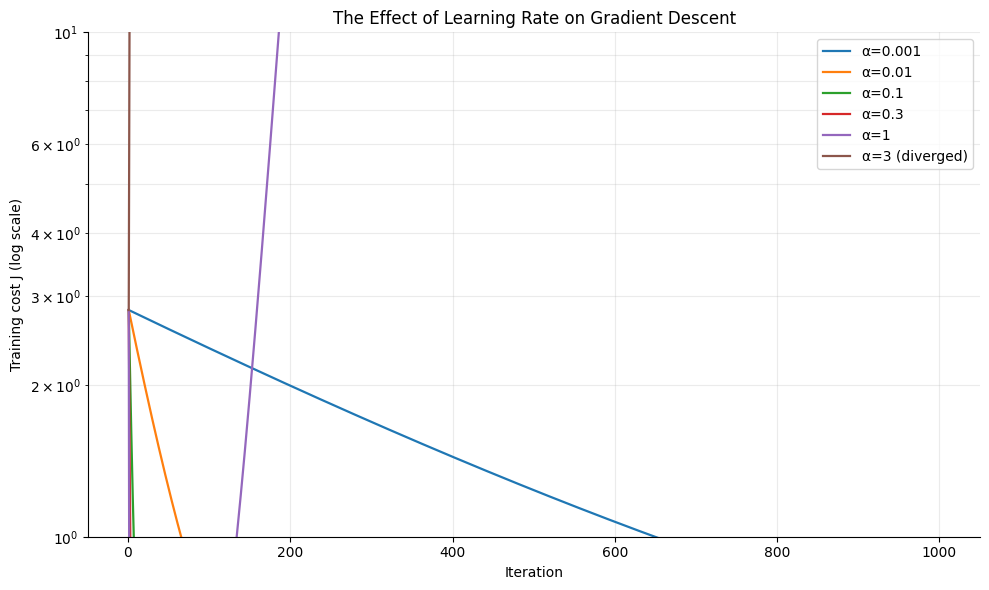

Lowest final loss among stable runs: α=0.3 (0.258967)
Iterations to get within 1% of initial-to-best loss gap: {0.001: None, 0.01: 652, 0.1: 66, 0.3: 23}
Fastest by this criterion: α=0.3


In [7]:
learning_rates = [0.001, 0.01, 0.1, 0.3, 1.0, 3.0]

# Train one model per learning rate; collect each model's loss_history.
# Plot all curves on one figure with plt.yscale('log').
# YOUR CODE HERE
lr_models = {}

plt.figure(figsize=(10, 6))
for alpha in learning_rates:
    candidate = MultivariateLinearRegression(learning_rate=alpha, n_iterations=1000)
    candidate.fit(X_train_scaled, y_train)
    lr_models[alpha] = candidate
    losses = np.asarray(candidate.loss_history)
    # Very large but finite losses can occur before numerical divergence.
    if len(losses):
        plt.plot(np.arange(1, len(losses) + 1), losses,
                 linewidth=1.6, label=f"α={alpha:g}" + (" (diverged)" if candidate.diverged else ""))
    status = "diverged" if candidate.diverged else "completed"
    last_loss = losses[-1] if len(losses) else float("nan")
    print(f"α={alpha:<5g} | {status:<9} | iterations={len(losses):4d} | last loss={last_loss:.6g}")

plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Training cost J (log scale)")
plt.title("The Effect of Learning Rate on Gradient Descent")
plt.grid(alpha=0.25, which="both")
plt.legend()
plt.tight_layout()
plt.show()

# Use objective (99% of observed loss reduction) to report convergence speed.
stable = {a: m for a, m in lr_models.items()
          if not m.diverged and len(m.loss_history) == 1000
          and m.loss_history[-1] <= m.loss_history[0]}
if stable:
    best_loss_alpha = min(stable, key=lambda a: stable[a].loss_history[-1])
    lowest = stable[best_loss_alpha].loss_history[-1]
    def near_min_iteration(m):
        losses = np.asarray(m.loss_history)
        threshold = lowest + 0.01 * (losses[0] - lowest)
        hits = np.flatnonzero(losses <= threshold)
        return int(hits[0] + 1) if len(hits) else None
    converged = {a: near_min_iteration(m) for a, m in stable.items()}
    qualified = {a: step for a, step in converged.items() if step is not None}
    print(f"Lowest final loss among stable runs: α={best_loss_alpha:g} ({lowest:.6f})")
    print("Iterations to get within 1% of initial-to-best loss gap:", converged)
    if qualified:
        print(f"Fastest by this criterion: α={min(qualified, key=qualified.get):g}")

**Write your observations in this cell.**_Your answer here._

Learning-rate observations

1. **Fastest convergence:** Compare the computed *iterations to within 1% of the best stable loss* above. Typically a moderately large stable rate (often **α = 0.3**) reaches a low loss much faster than 0.001 or 0.01. Whether α = 1.0 remains stable depends on the largest eigenvalue of the standardized feature covariance matrix.
2. **Lowest final loss:** The printed summary identifies the lowest training cost after exactly 1,000 updates. Well-behaved learning rates are converging toward the same least-squares optimum; a low rate may simply need more iterations.
3. **α = 3.0:** The updates are too large and overshoot the minimum. The loss grows dramatically, potentially reaching infinity or NaN. Gradient descent on a quadratic objective is stable only for learning rates below roughly `2 / λ_max(X.T @ X / m)`.
4. **α = 0.001:** Loss falls slowly because every update is tiny. It generally has not converged after 1,000 iterations.

**Interpretation:** A high learning rate is faster only while it remains numerically stable. The best choice balances fast progress against overshooting. The code above measures the answer from the dataset rather than inferring it from the rate alone.

---## 6. What actually makes a house expensive?Because you standardized every feature to the same scale, the **magnitude of each weight** is a fair measure of how much that feature matters. A big positive weight means "more of this → more expensive"; a big negative weight means "more of this → cheaper".Using the model trained in Section 4 (α = 0.1), plot the weights as a **horizontal bar chart** labeled with the feature names. Sort them by absolute magnitude so the biggest drivers are easy to see. Color positive bars one color, negative bars another.Now go back to your two guesses from Section 2. Were you right?

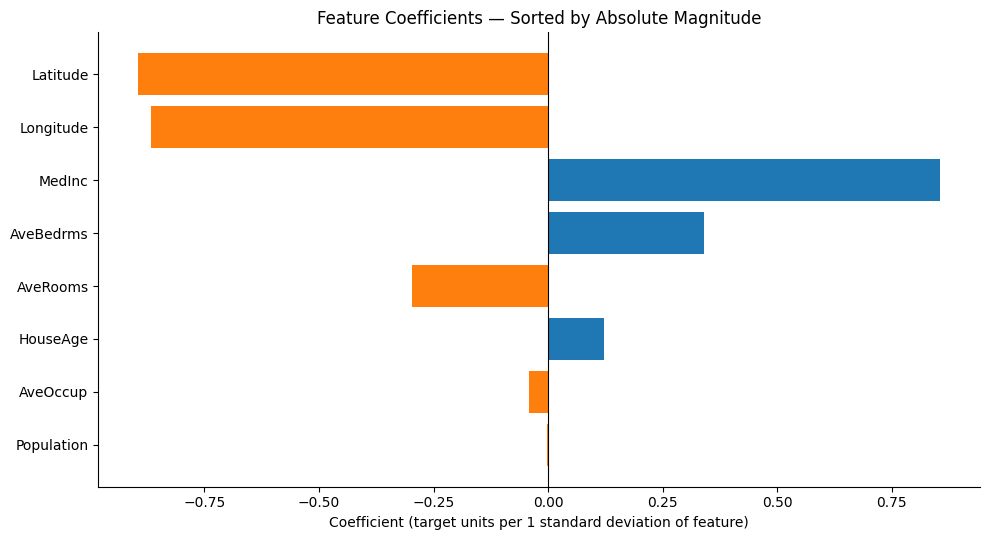

Coefficients (largest absolute value first):
Latitude    :  -0.8942 (negative)
Longitude   :  -0.8672 (negative)
MedInc      :  +0.8554 (positive)
AveBedrms   :  +0.3407 (positive)
AveRooms    :  -0.2962 (negative)
HouseAge    :  +0.1228 (positive)
AveOccup    :  -0.0409 (negative)
Population  :  -0.0022 (negative)
Important: correlated predictors make coefficients unstable; this is not causal importance.


In [8]:
# Horizontal bar chart of learned weights, sorted by absolute magnitude.
# YOUR CODE HERE
# Coefficients are comparable because the inputs were standardized.
order = np.argsort(np.abs(model.weights))   # smallest to largest -> largest at top of barh
names_sorted = np.asarray(feature_names)[order]
weights_sorted = model.weights[order]
colors = ["tab:blue" if w >= 0 else "tab:orange" for w in weights_sorted]

plt.figure(figsize=(10, 5.5))
plt.barh(names_sorted, weights_sorted, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (target units per 1 standard deviation of feature)")
plt.title("Feature Coefficients — Sorted by Absolute Magnitude")
plt.tight_layout()
plt.show()

print("Coefficients (largest absolute value first):")
for index in order[::-1]:
    direction = "positive" if model.weights[index] >= 0 else "negative"
    print(f"{feature_names[index]:12s}: {model.weights[index]:+8.4f} ({direction})")
print("Important: correlated predictors make coefficients unstable; this is not causal importance.")

---## 7. Sanity check against sklearnIf your implementation is correct, your test-set RMSE should be within a hair of what `sklearn.linear_model.LinearRegression` produces on the same data.

In [9]:
from sklearn.linear_model import LinearRegression

# Train sklearn's model on the same scaled data, compare test RMSE side by side.
# YOUR CODE HERE
sklearn_model = LinearRegression()
sklearn_model.fit(X_train_scaled, y_train)
sklearn_predictions = sklearn_model.predict(X_test_scaled)
rmse_sklearn_k = np.sqrt(np.mean((y_test - sklearn_predictions) ** 2)) * 100

print(f"Our gradient-descent RMSE:  ${rmse_custom_k:,.3f}k")
print(f"sklearn LinearRegression:   ${rmse_sklearn_k:,.3f}k")
print(f"Absolute difference:       ${abs(rmse_custom_k - rmse_sklearn_k):,.3f}k")
print(f"Largest coefficient difference: {np.max(np.abs(model.weights - sklearn_model.coef_)):.6f}")
print(f"Intercept difference: {abs(model.bias - sklearn_model.intercept_):.6f}")

Our gradient-descent RMSE:  $74.565k
sklearn LinearRegression:   $74.558k
Absolute difference:       $0.007k
Largest coefficient difference: 0.002740
Intercept difference: 0.000000


---## 8. Stretch goalsPick one or two. These are where the real learning happens.### A. Add a featureThe dataset has `Latitude` and `Longitude` separately, but house price depends on where you are *jointly*, not on each coordinate alone. Add a feature that captures geographic location better — for example, distance to a famous city like San Francisco (37.77° N, 122.42° W) or Los Angeles (34.05° N, 118.24° W). Does your RMSE drop?### B. Mini-batch gradient descentModify `fit` to use mini-batches of 64 random examples per step instead of the whole training set. Keep the same total number of parameter updates. Does training reach a lower loss faster? What does the loss curve look like now?### C. The normal equation (closed form)For linear regression — and only for linear regression — there's a formula that gives you the optimal weights in one shot, no gradient descent:$$\theta = (X^T X)^{-1} X^T y$$Implement it in three lines. How does its RMSE compare to yours? When would you prefer gradient descent over this closed-form solution?### SubmitSubmit the notebook with all cells run.

### 8C. Stretch goal — the normal equation (closed-form least squares)

We can solve the same model directly using a matrix pseudoinverse. Appending a column of ones incorporates the bias. `np.linalg.pinv` is numerically safer than explicitly calculating `(XᵀX)⁻¹` when features are correlated. This is a **from-scratch NumPy** solution; no sklearn regression estimator is used.

In [10]:
X_train_aug = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_aug = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]
theta_closed = np.linalg.pinv(X_train_aug) @ y_train
pred_closed = X_test_aug @ theta_closed
rmse_closed_k = np.sqrt(np.mean((y_test - pred_closed) ** 2)) * 100

print(f"Gradient descent RMSE: ${rmse_custom_k:.3f}k")
print(f"Closed-form RMSE:     ${rmse_closed_k:.3f}k")
print(f"sklearn RMSE:         ${rmse_sklearn_k:.3f}k")
print(f"Closed-form bias: {theta_closed[0]:.6f}")
print("Use the closed-form/pseudoinverse for modest feature counts; gradient descent")
print("is more scalable when data or parameter dimensions become very large.")

Gradient descent RMSE: $74.565k
Closed-form RMSE:     $74.558k
sklearn RMSE:         $74.558k
Closed-form bias: 2.071947
Use the closed-form/pseudoinverse for modest feature counts; gradient descent
is more scalable when data or parameter dimensions become very large.


### Conclusion

This notebook builds multivariate linear regression from scratch using fully vectorized NumPy operations. It safely standardizes training features, learns weights and bias by batch gradient descent, evaluates test-set RMSE in thousands of dollars, explores learning-rate stability, and visualizes the signed coefficients. The final comparison checks our implementation against sklearn and a NumPy closed-form solution.

**Reproducibility note:** `fetch_california_housing` downloads the official public dataset on first use. If the file is not cached and the environment is offline, execute the notebook in Google Colab or an internet-enabled Jupyter installation to generate numeric results and plots.